<a href="https://colab.research.google.com/github/daltee/pytorch-meetup-mbra/blob/dev/notebooks/pytorch_fundamentals_mbarara.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PyTorch Fundamentals — Your First Clothing Classifier
**PyTorch Community Meetup Mbarara · 25 minutes**

Goal: train a tiny neural network from scratch to classify clothing pictures. Runtime: CPU is sufficient.

**Next steps**

- Start a Python kernel and run the first code cell to check that PyTorch imports.

## 1. Tensors are the building blocks (3 minutes)
A tensor is a multidimensional array. Images in Fashion-MNIST are 28 × 28 pixels.

**Next steps**

- Predict the shape of a single Fashion-MNIST image before running the tensor example.

In [1]:
import torch
print("PyTorch version:",torch.__version__)
pixels = torch.rand(28, 28)
print("Single image shape:", pixels.shape)
print("Mean pixel value:", pixels.mean().item())

PyTorch version: 2.11.0+cpu
Single image shape: torch.Size([28, 28])
Mean pixel value: 0.5065285563468933


**Next steps**

- Change `torch.rand(28, 28)` to `torch.rand(2, 28, 28)` and rerun this cell to see how a batch adds a dimension.

## 2. Load clothing images (3 minutes)
Fashion-MNIST has 10 everyday clothing categories.

**Next steps**

- Run the dataset cell and choose two class names you expect the classifier to confuse.

In [2]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

transform = transforms.ToTensor()
train_full = datasets.FashionMNIST("./data", train=True, download=True, transform=transform)
test_full = datasets.FashionMNIST("./data", train=False, download=True, transform=transform)
classes = train_full.classes
# Smaller subset to ensure a CPU-friendly live workshop.
gen = torch.Generator().manual_seed(42)
train_ids = torch.randperm(len(train_full), generator=gen)[:6000].tolist()
train_data = Subset(train_full, train_ids)
test_data = Subset(test_full, list(range(1000)))
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128)
print(classes)

100%|██████████| 26.4M/26.4M [00:01<00:00, 22.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 343kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.29MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.1MB/s]

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


**Next steps**

- Run `print(len(train_data), len(test_data))` to confirm the workshop uses 6,000 training images and 1,000 test images.

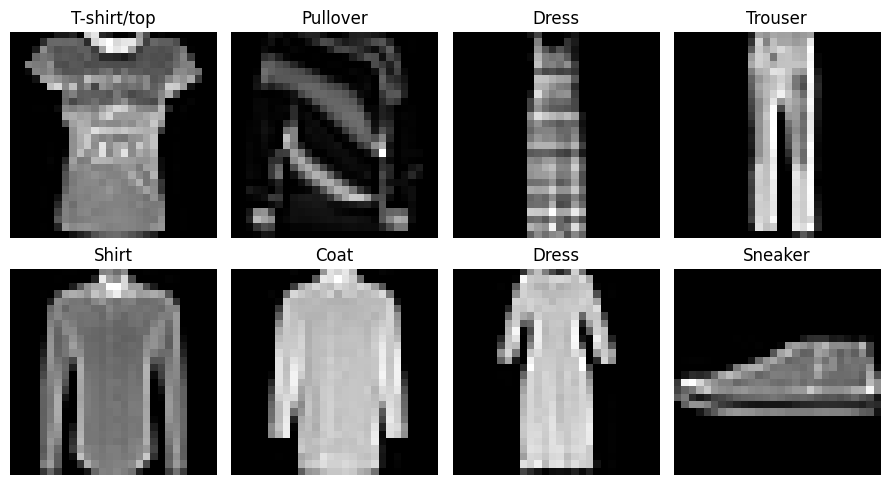

In [7]:
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(9, 5))
for ax, img, lab in zip(axes.flat, images[:8], labels[:8]):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(classes[lab.item()])
    ax.axis("off")
plt.tight_layout()

**Next steps**

- Run `print(images.shape, labels.shape)` and match the dimensions to batch size, channels, height, and width.

## 3. Define a neural network (4 minutes)
The model flattens each 28×28 image into 784 values and predicts one of 10 clothing classes.

**Next steps**

- Calculate the flattened input size, then check it against the first linear layer below.

In [8]:
from torch import nn
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10),
)
print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)


**Next steps**

- Run `print(model(images[:2]).shape)` to check that two images produce two rows of ten class scores.

## 4. Train (6 minutes)
Cross-entropy measures prediction mistakes. Backpropagation computes gradients; Adam updates weights.

**Next steps**

- Write down what you expect to happen to average loss from epoch 1 to epoch 2, then run the training cell.

In [9]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def train_one_epoch():
    model.train()
    total_loss = 0.0
    for x, y in train_loader:
        logits = model(x)
        loss = loss_fn(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(x)
    return total_loss / len(train_loader.dataset)

epochs = 2
for epoch in range(epochs):
    print(f"Epoch {epoch+1}: loss = {train_one_epoch():.3f}")

Epoch 1: loss = 1.180
Epoch 2: loss = 0.690


**Next steps**

- Record the loss for both epochs and compare it with your prediction.

## 5. Evaluate and inspect predictions (4 minutes)
The test subset is kept separate from training.

**Next steps**

- Run the accuracy cell before viewing individual predictions so you have a baseline for the whole test subset.

In [10]:
model.eval()
correct = 0
with torch.inference_mode():
    for x, y in test_loader:
        pred = model(x).argmax(dim=1)
        correct += (pred == y).sum().item()
print(f"Accuracy on 1,000 held-out test images: {correct / len(test_data):.1%}")

Accuracy on 1,000 held-out test images: 79.0%


**Next steps**

- Record the test accuracy and calculate how many of the 1,000 images were misclassified using `len(test_data) - correct`.

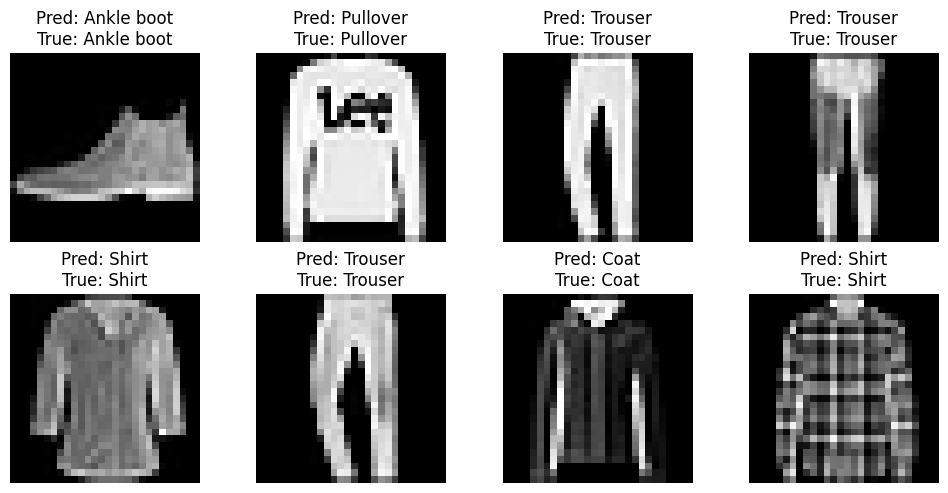

In [11]:
x, y = next(iter(test_loader))
with torch.inference_mode():
    pred = model(x).argmax(dim=1)
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x[i].squeeze(), cmap="gray")
    ax.set_title(f"Pred: {classes[pred[i]]}\nTrue: {classes[y[i]]}")
    ax.axis("off")
plt.tight_layout()

**Next steps**

- Compare the predicted and true labels in each tile. If all eight match, run `print((pred != y).nonzero().flatten().tolist())` to find a mistake elsewhere in the batch.

## 6. Your turn (last 3 minutes)
- Change the hidden layer from 128 to 64 or 256 units.
- Set `epochs = 3`, then restart the kernel and run all cells. Does accuracy improve?
- Look at an incorrect prediction. Why might the model be confused?

**Bridge to workshop 2:** We trained all weights from scratch. What if we could reuse features already learned from millions of pictures?

**Next steps**

- Pick one change, restart the kernel, and run all cells. Compare the new accuracy with your baseline and record what you changed.